In [14]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.metrics import mean_squared_error,r2_score
import pandas as pd

In [15]:
data=load_diabetes()
x,y=data.data,data.target
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=.2,random_state=42
)

In [16]:
lin =LinearRegression().fit(x_train,y_train)

In [17]:
ridge_cv=GridSearchCV(
    Ridge(),
    {"alpha":[.01,.1,1,10,100]},
    cv=5,
    scoring="neg_mean_squared_error"
)
ridge_cv.fit(x_train,y_train)
ridge=ridge_cv.best_estimator_

In [18]:
lasso_cv=GridSearchCV(
    Lasso(max_iter=1000),
    {"alpha":[0.01,.1,1,10,100]},
    cv=5,
    scoring="neg_mean_squared_error"
)
lasso_cv.fit(x_train,y_train)
lasso=lasso_cv.best_estimator_


In [19]:
rows=[]
models={
    "Linear":lin,
    "Ridge":ridge,
    "Lasso":lasso
}

In [23]:
for name,model in models.items():
    y_pred=model.predict(x_test,)
    rows.append([
        name,
        mean_squared_error(y_test,y_pred),
        r2_score(y_test,y_pred)
    ])

In [24]:
print("Best Ridge Regression:",ridge_cv.best_params_)
print("Best Lasso Regression:",lasso_cv.best_params_)

Best Ridge Regression: {'alpha': 0.1}
Best Lasso Regression: {'alpha': 0.1}


In [29]:
print(pd.DataFrame(
    rows,
    columns=["Models","MSE","R2"]
))

   Models          MSE        R2
0  Linear  2900.193628  0.452603
1   Ridge  2856.486888  0.460852
2   Lasso  2798.193485  0.471855


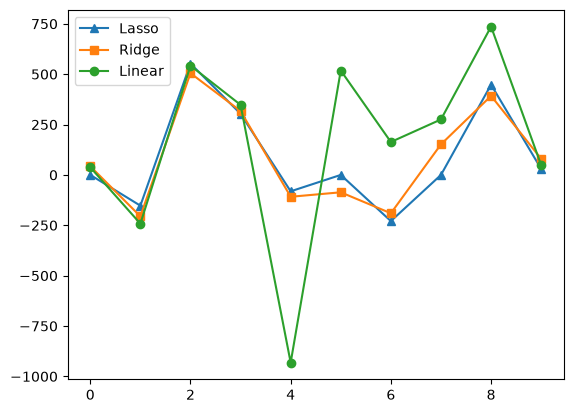

In [33]:
import matplotlib.pyplot as plt
plt.plot(lasso.coef_,"^-",label="Lasso")
plt.plot(ridge.coef_,"s-",label="Ridge")
plt.plot(lin.coef_,"o-",label="Linear")
plt.legend()
plt.show()